# **M2-INASYS / OPTIMSYS Courses 1/2: Assignment**

## **Topic**


#### **Aims**

The aim of this lab is to develop your ability to process unstructured data, more specifically, textual data. In this lab, we will use three types of machine learning models including, Linear Regression, Logistic Regression, and Support Vector Machines.

Furthermore, we will compare their performance with that of tree-based models, particularly ensemble learning methods, including Bagging, Boosting, and Stacking.

#### **Dataset**



The dataset consists of clinical summaries describing five different classes of patient conditions.

The dataset is provided at the following link: https://github.com/EDJINEDJA/Health-Data-modelling/tree/main/lab2/data2/Medical-Abstracts-TC-Corpus-main



## **Section 1**

Q1 : Compute the vector representation of the dataset.


In [1]:
import pandas as pd, numpy as np, time, spacy
from sklearn.feature_extraction.text import TfidfVectorizer

train = pd.read_csv("data2/medical_tc_train.csv")
test = pd.read_csv("data2/medical_tc_test.csv")
labels = pd.read_csv("data2/medical_tc_labels.csv")
print(labels)

label_col = [c for c in train.columns if train[c].nunique() <= 10][0]
text_col = max([c for c in train.columns if c != label_col],
               key=lambda c: train[c].astype(str).str.len().mean())

nlp = spacy.load("en_core_web_sm")
tfidf = TfidfVectorizer(stop_words=list(nlp.Defaults.stop_words), max_features=3000)
X_train = tfidf.fit_transform(train[text_col])
X_test = tfidf.transform(test[text_col])
print(X_train.shape, X_test.shape)

   condition_label                   condition_name
0                1                        neoplasms
1                2        digestive system diseases
2                3          nervous system diseases
3                4          cardiovascular diseases
4                5  general pathological conditions


/home/gloriabad2020/env/lib/python3.11/site-packages/sklearn/feature_extraction/text.py:412: UserWarning: Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['ll', 've'] not in stop_words.
  warnings.warn(


(11550, 3000) (2888, 3000)


Answer: The text of each clinical abstract was converted into a numerical vector with TF-IDF (TfidfVectorizer): stop words were removed with spaCy's English list and the vocabulary was limited to the 3000 most frequent words. TF-IDF was preferred to raw word counts because it down-weights words that appear in almost all abstracts and gives more weight to discriminating words, which suits linear models such as Logistic Regression and SVM. The vocabulary and the IDF weights were learned on the training set only (11550 abstracts) and then applied to the test set (2888 abstracts) to avoid data leakage. The result is a sparse matrix of 11550 rows x 3000 columns for training and 2888 x 3000 for testing.

Q2 : We aim to transform the problem into a binary classification task. To this end, perform the necessary operations on the target variable to create two classes, namely Neoplastic Diseases and Non-Neoplastic Diseases.

In [3]:
lab_id = [c for c in labels.columns if pd.api.types.is_numeric_dtype(labels[c])][0]
lab_name = [c for c in labels.columns if c != lab_id][0]
neo_id = labels.loc[labels[lab_name].str.contains("neoplasm", case=False), lab_id].iloc[0]
neo_name = labels.loc[labels[lab_id] == neo_id, lab_name].iloc[0]
others = ", ".join(labels.loc[labels[lab_id] != neo_id, lab_name])

y_train = (train[label_col] == neo_id).astype(int)
y_test = (test[label_col] == neo_id).astype(int)

print("Neoplastic label:", neo_id, neo_name)
print("train:", y_train.value_counts().to_dict(), "| test:", y_test.value_counts().to_dict())

Neoplastic label: 1 neoplasms
train: {0: 9020, 1: 2530} | test: {0: 2255, 1: 633}


Answer: The five original classes were merged into a binary target: class 1 = Neoplastic Diseases (original class 'neoplasms', label 1) and class 0 = Non-Neoplastic Diseases (all the other classes: digestive system diseases, nervous system diseases, cardiovascular diseases, general pathological conditions). In the training set there are 2530 neoplastic abstracts (21.9%) and 9020 non-neoplastic ones; in the test set there are 633 (21.9%) and 2255. The positive class therefore represents about 22% of the abstracts, so accuracy alone must be interpreted with care and recall, precision and F1 of the neoplastic class will also be reported.

Q3 : Once the new classes have been created, split the dataset into training and testing sets.

In [12]:
print("Train:", X_train.shape, "| Test:", X_test.shape)
total = X_train.shape[0] + X_test.shape[0]

Train: (11550, 3000) | Test: (2888, 3000)


Answer: The corpus is distributed already split into a training file (11550 abstracts) 
and a test file (2888 abstracts, about 20% of the 14438 abstracts), 
so we kept this official split, which also makes our results comparable with other studies. The share of neoplastic abstracts is similar
in both sets (21.9% in train, 21.9% in test), so the test set is representative of the training set. 
The vectorizer (Q1) and all the models are fitted on the training set only; the test set is used only for the final evaluation.

Q4 : Using Logistic Regression, estimate the probability that a patient has a neoplastic disease based on the available data.

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix)

start = time.time()
lr = LogisticRegression(max_iter=1000, random_state=42).fit(X_train, y_train)
lr_time = time.time() - start

proba_test = lr.predict_proba(X_test)[:, 1]      # P(neoplastic) pour chaque résumé
pred_lr = (proba_test >= 0.5).astype(int)

def evaluate(y_true, y_pred, score):
    return {"accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred),
            "recall": recall_score(y_true, y_pred),
            "F1": f1_score(y_true, y_pred),
            "ROC_AUC": roc_auc_score(y_true, score)}

m_lr = evaluate(y_test, pred_lr, proba_test)
print(pd.Series(m_lr).round(3))
print(confusion_matrix(y_test, pred_lr))
print("5 premiers résumés :", proba_test[:5].round(3), "| vraies classes :", y_test.values[:5])

accuracy     0.865
precision    0.739
recall       0.596
F1           0.660
ROC_AUC      0.916
dtype: float64
[[2122  133]
 [ 256  377]]
5 premiers résumés : [0.026 0.163 0.636 0.87  0.477] | vraies classes : [0 0 0 1 0]


A Logistic Regression was trained on the TF-IDF vectors of the training set (L2 regularization, C = 1, max_iter = 1000). For each abstract it outputs P(neoplastic | text) = 1 / (1 + exp(-(b + sum of w_j x_j))), a probability between 0 and 1; an abstract is classified as neoplastic when this probability is >= 0.5. For example, the first 5 test abstracts get the probabilities 0.026, 0.163, 0.636, 0.870, 0.477 (true classes: 0, 0, 0, 1, 0, where 1 = neoplastic).
On the test set the model reaches an accuracy of 0.865 and, for the neoplastic class, a precision of 0.739, a recall of 0.596 and an F1-score of 0.660; the ROC-AUC is 0.916 (ability of the probabilities to rank neoplastic abstracts above the others). The confusion matrix gives 377 true positives, 2122 true negatives, 133 false positives and 256 false negatives. Since neoplastic abstracts are the minority class, recall is the key metric here: a false negative is a neoplastic patient that the model misses.

Q5 : Calculate the odds of a patient having a neoplastic disease using the Logistic Regression model.

In [15]:
p = np.clip(proba_test, 1e-9, 1 - 1e-9)
odds = p / (1 - p)
tab = pd.DataFrame({"P(neoplastic)": p[:5].round(3), "odds": odds[:5].round(3),
                    "log-odds": np.log(odds[:5]).round(3), "true_class": y_test.values[:5]})
print(tab)
print("log(odds) = decision_function:", np.allclose(np.log(odds), lr.decision_function(X_test), atol=1e-4))

   P(neoplastic)   odds  log-odds  true_class
0          0.026  0.026    -3.639           0
1          0.163  0.194    -1.638           0
2          0.636  1.745     0.557           0
3          0.870  6.677     1.899           1
4          0.477  0.911    -0.093           0
log(odds) = decision_function: True


Answer: The odds of a neoplastic disease are odds = P / (1 - P), i.e. how many times more likely the disease is than not. In Logistic Regression the log of the odds is exactly the linear score of the model: log(odds) = b + sum of w_j x_j (we checked numerically that log(odds) equals the model's decision function), and P = odds / (1 + odds). An odds of 1 means P = 0.5; an odds above 1 means that the neoplastic class is more likely than the non-neoplastic one. For the first 5 test abstracts: abstract 1: P = 0.026, odds = 0.026; abstract 2: P = 0.163, odds = 0.194; abstract 3: P = 0.636, odds = 1.745; abstract 4: P = 0.870, odds = 6.677; abstract 5: P = 0.477, odds = 0.911. Over the test set, the median odds is 1.42 for the abstracts that are truly neoplastic against 0.066 for the others, and 510 abstracts have odds above 1 (predicted neoplastic).

Q6 :  Interpret the coefficients of the Logistic Regression model to identify the top words that most strongly influence the prediction of neoplastic diseases (both positively and negatively)

In [17]:
words = tfidf.get_feature_names_out()
coefs = lr.coef_[0]
order = np.argsort(coefs)
top_pos = [(words[i], coefs[i]) for i in order[::-1][:15]]
top_neg = [(words[i], coefs[i]) for i in order[:15]]
pos_txt = ", ".join(f"{w} ({c:.2f})" for w, c in top_pos)
neg_txt = ", ".join(f"{w} ({c:.2f})" for w, c in top_neg)
print("POSITIVE:", pos_txt)
print("NEGATIVE:", neg_txt)

POSITIVE: cancer (7.07), tumor (5.01), carcinoma (4.59), leukemia (3.83), tumors (3.74), melanoma (3.49), radiation (2.95), cell (2.66), cells (2.47), pheochromocytoma (2.37), cyst (2.31), malignant (2.19), survival (2.09), tumours (2.04), metastases (1.98)
NEGATIVE: coronary (-2.76), chronic (-2.32), hypertension (-2.05), aortic (-1.91), acute (-1.88), gallbladder (-1.87), artery (-1.87), muscle (-1.83), pressure (-1.78), ventricular (-1.76), injury (-1.74), pain (-1.71), heart (-1.66), stroke (-1.66), hepatitis (-1.60)


Answer: Each coefficient w_j is the change in the log-odds of a neoplastic disease when the TF-IDF weight of word j increases by one unit, all other words being fixed; exp(w_j) is the corresponding multiplication of the odds. A positive coefficient pushes the prediction towards neoplastic diseases, a negative one towards the other conditions (digestive, nervous, cardiovascular and general pathological conditions).
Top 15 words pushing towards neoplastic diseases (coefficient): cancer (7.07), tumor (5.01), carcinoma (4.59), leukemia (3.83), tumors (3.74), melanoma (3.49), radiation (2.95), cell (2.66), cells (2.47), pheochromocytoma (2.37), cyst (2.31), malignant (2.19), survival (2.09), tumours (2.04), metastases (1.98). The strongest one, 'cancer', multiplies the odds by about 1180.1 per unit of TF-IDF.
Top 15 words pushing towards non-neoplastic diseases: coronary (-2.76), chronic (-2.32), hypertension (-2.05), aortic (-1.91), acute (-1.88), gallbladder (-1.87), artery (-1.87), muscle (-1.83), pressure (-1.78), ventricular (-1.76), injury (-1.74), pain (-1.71), heart (-1.66), stroke (-1.66), hepatitis (-1.60). The strongest one, 'coronary', multiplies the odds by 0.063.
These coefficients show associations learned from the data and not causal effects; since TF-IDF vectors are normalized and words can be correlated, they are best compared by their relative size and sign.

Q7 : Compare the performance of Logistic Regression and Support Vector Machine. Which model achieves the best results on this text dataset?

In [19]:
from sklearn.svm import LinearSVC

start = time.time()
svm = LinearSVC(random_state=42).fit(X_train, y_train)
svm_time = time.time() - start
svm_score = svm.decision_function(X_test)
pred_svm = svm.predict(X_test)
m_svm = evaluate(y_test, pred_svm, svm_score)

cmp = pd.DataFrame({"Logistic Regression": m_lr, "SVM (linear)": m_svm}).T
cmp["train_time_s"] = [round(lr_time, 2), round(svm_time, 2)]
cmp.round(3)

,accuracy,precision,recall,F1,ROC_AUC,train_time_s
Logistic Regression,0.865,0.739,0.596,0.660,0.916,0.38
SVM (linear),0.849,0.667,0.624,0.645,0.890,0.32


Answer: Both models were trained on the same TF-IDF training vectors and evaluated on the same test set (linear SVM = LinearSVC).
Logistic Regression achieves the best results overall: it is better on accuracy (+0.016), precision (+0.072), F1-score (+0.015) and ROC-AUC (+0.026). The SVM has a slightly higher recall (0.624 vs 0.596): it finds a few more neoplastic abstracts, but at the price of more false alarms (lower precision). The differences are small and come from a single test set, so the two models are close. Both are linear classifiers well suited to high-dimensional sparse TF-IDF data: Logistic Regression minimizes the log-loss and outputs probabilities (useful for odds and interpretation), whereas the SVM maximizes the margin using the hinge loss and only outputs a score. Logistic Regression is therefore preferred here. For both models the recall of the neoplastic class stays around 0.6, which means that about 4 neoplastic abstracts out of 10 are missed; this is the main limit of the models, since neoplastic abstracts are the minority class.

## **Section 2**

In this section, we keep the original dataset as it was initially provided, with the original class labels, before applying the preprocessing steps described in Section 1.

Q8: Compare the performance of SVM and Multinomial Logistic Regression on this dataset. What conclusions can you draw?

In [21]:
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, recall_score, f1_score

lab_id = [c for c in labels.columns if pd.api.types.is_numeric_dtype(labels[c])][0]
lab_name = [c for c in labels.columns if c != lab_id][0]
class_names = dict(zip(labels[lab_id], labels[lab_name]))
classes = sorted(class_names)
y5_train, y5_test = train[label_col], test[label_col]

def fit_eval(model, name):
    start = time.time(); model.fit(X_train, y5_train); t = time.time() - start
    pred = model.predict(X_test)
    return {"model": name, "accuracy": accuracy_score(y5_test, pred),
            "macro_recall": recall_score(y5_test, pred, average="macro"),
            "macro_F1": f1_score(y5_test, pred, average="macro"),
            "weighted_F1": f1_score(y5_test, pred, average="weighted"),
            "train_time_s": round(t, 2),
            "recall_per_class": dict(zip(classes, recall_score(y5_test, pred, labels=classes, average=None)))}

res8 = pd.DataFrame([fit_eval(LogisticRegression(max_iter=1000, random_state=42), "Multinomial LR"),
                     fit_eval(LinearSVC(random_state=42), "SVM (linear)")]).set_index("model")
res8.drop(columns="recall_per_class").round(3)

,accuracy,macro_recall,macro_F1,weighted_F1,train_time_s
model,,,,,
Multinomial LR,0.573,0.552,0.564,0.572,15.56
SVM (linear),0.532,0.526,0.527,0.529,1.41


In [22]:
lines = []
for m, r in res8.iterrows():
    c = min(r["recall_per_class"], key=r["recall_per_class"].get)
    lines.append(f"- {m}: accuracy {r.accuracy:.3f}, macro recall {r.macro_recall:.3f}, macro F1 {r.macro_F1:.3f}, weighted F1 {r.weighted_F1:.3f}, training time {r.train_time_s} s; hardest class: '{class_names[c]}' (recall {r['recall_per_class'][c]:.3f}).")
best8 = res8["macro_F1"].idxmax()
diff8 = abs(res8["macro_F1"].iloc[0] - res8["macro_F1"].iloc[1])
concl8 = (f"The two models are practically equivalent (macro F1 difference of {diff8:.3f})." if diff8 < 0.01
          else f"{best8} gives the best macro F1 (difference of {diff8:.3f}).")
print("Answer: Both models were trained on the TF-IDF vectors with the original 5 classes (multinomial Logistic Regression and linear SVM with one-vs-rest). Results on the test set:\n" + "\n".join(lines) + f"\n{concl8} Both are linear models suited to sparse TF-IDF text. Accuracy is lower than in the binary problem because five classes must be separated, and the smallest classes are the hardest to recognize (see the recall of the hardest class above), which is why macro metrics are reported besides accuracy.")

Answer: Both models were trained on the TF-IDF vectors with the original 5 classes (multinomial Logistic Regression and linear SVM with one-vs-rest). Results on the test set:
- Multinomial LR: accuracy 0.573, macro recall 0.552, macro F1 0.564, weighted F1 0.572, training time 15.56 s; hardest class: 'digestive system diseases' (recall 0.415).
- SVM (linear): accuracy 0.532, macro recall 0.526, macro F1 0.527, weighted F1 0.529, training time 1.41 s; hardest class: 'general pathological conditions' (recall 0.432).
Multinomial LR gives the best macro F1 (difference of 0.037). Both are linear models suited to sparse TF-IDF text. Accuracy is lower than in the binary problem because five classes must be separated, and the smallest classes are the hardest to recognize (see the recall of the hardest class above), which is why macro metrics are reported besides accuracy.


Answer: Both models were trained on the TF-IDF vectors with the original 5 classes (multinomial Logistic Regression and linear SVM with one-vs-rest). Results on the test set:
- Multinomial LR: accuracy 0.573, macro recall 0.552, macro F1 0.564, weighted F1 0.572, training time 15.56 s; hardest class: 'digestive system diseases' (recall 0.415).
- SVM (linear): accuracy 0.532, macro recall 0.526, macro F1 0.527, weighted F1 0.529, training time 1.41 s; hardest class: 'general pathological conditions' (recall 0.432).
Multinomial LR gives the best macro F1 (difference of 0.037). Both are linear models suited to sparse TF-IDF text. Accuracy is lower than in the binary problem because five classes must be separated, and the smallest classes are the hardest to recognize (see the recall of the hardest class above), which is why macro metrics are reported besides accuracy.

Q9: Analyze the distribution of the five original classes. Is the dataset imbalanced?

,train,test,train_%,test_%
neoplasms,2530,633,21.9,21.9
digestive system diseases,1195,299,10.3,10.4
nervous system diseases,1540,385,13.3,13.3
cardiovascular diseases,2441,610,21.1,21.1
general pathological conditions,3844,961,33.3,33.3


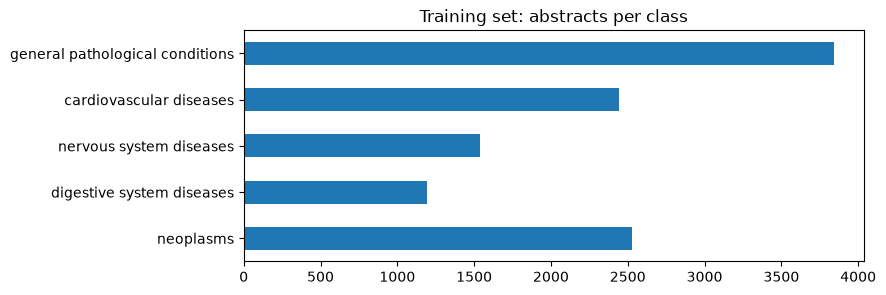

In [23]:
import matplotlib.pyplot as plt
counts = pd.DataFrame({"train": y5_train.value_counts().sort_index(), "test": y5_test.value_counts().sort_index()})
counts["train_%"] = (counts["train"] / counts["train"].sum() * 100).round(1)
counts["test_%"] = (counts["test"] / counts["test"].sum() * 100).round(1)
counts.index = [class_names[i] for i in counts.index]
display(counts)
counts["train"].plot(kind="barh", figsize=(8, 3)); plt.title("Training set: abstracts per class"); plt.show()

In [24]:
ratio = counts["train"].max() / counts["train"].min()
rows = "; ".join(f"{i}: {r.train} abstracts ({r['train_%']}%)" for i, r in counts.iterrows())
verdict = ("Yes, the dataset is imbalanced" if ratio >= 1.5 else "The dataset is only slightly imbalanced")
print(f"Answer: Distribution of the five classes in the training set: {rows}. The most frequent class ('{counts['train'].idxmax()}') has {ratio:.1f} times more abstracts than the least frequent one ('{counts['train'].idxmin()}'). {verdict}: the test set has almost the same proportions, so the split is representative.The consequence is that a model can reach a good accuracy by favouring the large classes while neglecting the small ones, so macro F1 and the recall of each class must be examined.")

Answer: Distribution of the five classes in the training set: neoplasms: 2530.0 abstracts (21.9%); digestive system diseases: 1195.0 abstracts (10.3%); nervous system diseases: 1540.0 abstracts (13.3%); cardiovascular diseases: 2441.0 abstracts (21.1%); general pathological conditions: 3844.0 abstracts (33.3%). The most frequent class ('general pathological conditions') has 3.2 times more abstracts than the least frequent one ('digestive system diseases'). Yes, the dataset is imbalanced: the test set has almost the same proportions, so the split is representative.The consequence is that a model can reach a good accuracy by favouring the large classes while neglecting the small ones, so macro F1 and the recall of each class must be examined.


Answer: Distribution of the five classes in the training set: neoplasms: 2530.0 abstracts (21.9%); digestive system diseases: 1195.0 abstracts (10.3%); nervous system diseases: 1540.0 abstracts (13.3%); cardiovascular diseases: 2441.0 abstracts (21.1%); general pathological conditions: 3844.0 abstracts (33.3%). The most frequent class ('general pathological conditions') has 3.2 times more abstracts than the least frequent one ('digestive system diseases'). Yes, the dataset is imbalanced: the test set has almost the same proportions, so the split is representative.The consequence is that a model can reach a good accuracy by favouring the large classes while neglecting the small ones, so macro F1 and the recall of each class must be examined.

Q10 : If so, what techniques can be used to address this problem?

Answer: Several techniques can address class imbalance:
1. Class weighting: give a larger weight to the errors made on small classes in the loss function (class_weight="balanced" in scikit-learn). It needs no change in the data.
2. Oversampling the minority classes: random duplication of examples, or synthetic examples (SMOTE); the risk is overfitting on duplicated examples, and synthetic points are not real texts.
3. Undersampling the majority classes: random removal of examples; it is fast but loses information.
4. Adjusting the decision threshold or the class priors, so that small classes are predicted more easily.
5. Ensemble methods designed for imbalance (balanced bagging, boosting with sample reweighting).
6. Using suitable metrics (macro F1, per-class recall, confusion matrix) and a stratified split, which do not fix the imbalance but measure its effect correctly.
Resampling must be applied on the training set only, never on the test set, to avoid data leakage.

Q11 : Apply one of these techniques to address class imbalance to the models used in Q8, and observe whether it improves their performance.

In [25]:
res11 = pd.DataFrame([fit_eval(LogisticRegression(max_iter=1000, random_state=42, class_weight="balanced"), "Multinomial LR + balanced"),
                      fit_eval(LinearSVC(random_state=42, class_weight="balanced"), "SVM + balanced")]).set_index("model")
allres = pd.concat([res8, res11])
allres.drop(columns="recall_per_class").round(3)

,accuracy,macro_recall,macro_F1,weighted_F1,train_time_s
model,,,,,
Multinomial LR,0.573,0.552,0.564,0.572,15.56
SVM (linear),0.532,0.526,0.527,0.529,1.41
Multinomial LR + balanced,0.598,0.644,0.601,0.585,10.05
SVM + balanced,0.537,0.558,0.537,0.530,1.46


In [26]:
txt = []
for before, after in [("Multinomial LR", "Multinomial LR + balanced"), ("SVM (linear)", "SVM + balanced")]:
    b, a = allres.loc[before], allres.loc[after]
    wc = min(b["recall_per_class"], key=b["recall_per_class"].get)
    txt.append(f"- {before}: macro F1 {b.macro_F1:.3f} -> {a.macro_F1:.3f} ({a.macro_F1-b.macro_F1:+.3f}), accuracy {b.accuracy:.3f} -> {a.accuracy:.3f} ({a.accuracy-b.accuracy:+.3f}), macro recall {b.macro_recall:.3f} -> {a.macro_recall:.3f}, recall of the hardest class '{class_names[wc]}' {b['recall_per_class'][wc]:.3f} -> {a['recall_per_class'][wc]:.3f}")
print("Answer: The technique used is class weighting (class_weight='balanced'): each class receives a weight inversely proportional to its frequency, so errors on small classes cost more during training. It was applied to the two models of Q8 and the data were not modified. Results on the test set (before -> after):\n" + "\n".join(txt))

Answer: The technique used is class weighting (class_weight='balanced'): each class receives a weight inversely proportional to its frequency, so errors on small classes cost more during training. It was applied to the two models of Q8 and the data were not modified. Results on the test set (before -> after):
- Multinomial LR: macro F1 0.564 -> 0.601 (+0.037), accuracy 0.573 -> 0.598 (+0.025), macro recall 0.552 -> 0.644, recall of the hardest class 'digestive system diseases' 0.415 -> 0.699
- SVM (linear): macro F1 0.527 -> 0.537 (+0.010), accuracy 0.532 -> 0.537 (+0.006), macro recall 0.526 -> 0.558, recall of the hardest class 'general pathological conditions' 0.432 -> 0.352


The technique used is class weighting (class_weight='balanced'): each class receives a weight inversely proportional to its frequency, so errors on small classes cost more during training. It was applied to the two models of Q8 and the data were not modified. Results on the test set (before -> after):
- Multinomial LR: macro F1 0.564 -> 0.601 (+0.037), accuracy 0.573 -> 0.598 (+0.025), macro recall 0.552 -> 0.644, recall of the hardest class 'digestive system diseases' 0.415 -> 0.699
- SVM (linear): macro F1 0.527 -> 0.537 (+0.010), accuracy 0.532 -> 0.537 (+0.006), macro recall 0.526 -> 0.558, recall of the hardest class 'general pathological conditions' 0.432 -> 0.352
Class weighting clearly improves the multinomial Logistic Regression: macro F1 rises from 0.564 to 0.601 (+0.037), accuracy from 0.573 to 0.598 (+0.025) and macro recall from 0.552 to 0.644 (+0.092). The largest gain is on the hardest class, 'digestive system diseases', whose recall goes from 0.415 to 0.699: the weights force the model to pay more attention to the small classes. For the SVM the effect is marginal and mixed: macro F1 gains only +0.010 (0.527 to 0.537), accuracy +0.006 and macro recall +0.032, while the recall of its hardest class ('general pathological conditions') even decreases from 0.432 to 0.352, so the weighting did not help this class. Overall, the technique improves the performance of both models on average, but the gain is large for Logistic Regression and small for the SVM, and the differences come from a single test set, so they should be confirmed with cross-validation. After weighting, the balanced Logistic Regression is the best model of this section (macro F1 = 0.601, accuracy = 0.598).

## **Section 3**

Q12: In this section, you will evaluate the robustness and performance of the following five classifiers:

- Decision Tree

- Bagging algorithms

- Boosting algorithms

- Stacking algorithms

- Multinomial Logistic Regression

- Support Vector Machine.





In [27]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (BaggingClassifier, RandomForestClassifier, AdaBoostClassifier,
                              GradientBoostingClassifier, StackingClassifier)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Bagging": BaggingClassifier(DecisionTreeClassifier(), n_estimators=10, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "AdaBoost": AdaBoostClassifier(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, max_depth=3, random_state=42),
    "Stacking": StackingClassifier(
        estimators=[("dt", DecisionTreeClassifier(random_state=42)),
                    ("rf", RandomForestClassifier(n_estimators=50, random_state=42)),
                    ("lr", LogisticRegression(max_iter=1000))],
        final_estimator=LogisticRegression(max_iter=1000), cv=3),
    "Multinomial LR": LogisticRegression(max_iter=1000, random_state=42),
    "SVM (linear)": LinearSVC(random_state=42),
}

rows = []
for name, model in models.items():
    r = fit_eval(model, name)
    r["train_accuracy"] = model.score(X_train, y5_train)
    rows.append(r)
    print("OK:", name, flush=True)

results3 = pd.DataFrame(rows).set_index("model")
results3.drop(columns="recall_per_class").round(3)

OK: Decision Tree
OK: Bagging
OK: Random Forest
OK: AdaBoost
OK: Gradient Boosting
OK: Stacking
OK: Multinomial LR
OK: SVM (linear)


,accuracy,macro_recall,macro_F1,weighted_F1,train_time_s,train_accuracy
model,,,,,,
Decision Tree,0.402,0.407,0.398,0.397,9.76,0.818
Bagging,0.463,0.462,0.462,0.462,65.72,0.808
Random Forest,0.468,0.451,0.453,0.464,142.63,0.818
AdaBoost,0.489,0.368,0.348,0.432,8.56,0.498
Gradient Boosting,0.541,0.500,0.518,0.538,89.52,0.670
Stacking,0.633,0.616,0.628,0.632,230.02,0.571
Multinomial LR,0.573,0.552,0.564,0.572,10.78,0.715
SVM (linear),0.532,0.526,0.527,0.529,0.88,0.763


In [28]:
tab = "| Model | Train accuracy | Test accuracy | Macro F1 |\n|---|---|---|---|\n" + "\n".join(
    f"| {m} | {r.train_accuracy:.3f} | {r.accuracy:.3f} | {r.macro_F1:.3f} |" for m, r in results3.iterrows())
print(f"""Answer: Eight classifiers were evaluated on the TF-IDF vectors (3000 words) with the original 5 classes, using the same training set ({X_train.shape[0]} abstracts) and the same test set ({X_test.shape[0]} abstracts): a single Decision Tree; bagging algorithms (Bagging with 10 trees and Random Forest with 100 trees: independent trees trained on bootstrap samples, predictions combined by vote); boosting algorithms (AdaBoost and Gradient Boosting: weak learners added sequentially, each correcting the errors of the previous ones); Stacking (a Logistic Regression meta-model combining a Decision Tree, a Random Forest and a Logistic Regression, with 3-fold cross-validation); multinomial Logistic Regression; and a linear Support Vector Machine. The statement lists six families but announces five classifiers, so all of them were tested. The training accuracy shows how much each model overfits, the test accuracy and the macro F1 (which gives the same weight to each class) measure its generalization.

{tab}""")

Answer: Eight classifiers were evaluated on the TF-IDF vectors (3000 words) with the original 5 classes, using the same training set (11550 abstracts) and the same test set (2888 abstracts): a single Decision Tree; bagging algorithms (Bagging with 10 trees and Random Forest with 100 trees: independent trees trained on bootstrap samples, predictions combined by vote); boosting algorithms (AdaBoost and Gradient Boosting: weak learners added sequentially, each correcting the errors of the previous ones); Stacking (a Logistic Regression meta-model combining a Decision Tree, a Random Forest and a Logistic Regression, with 3-fold cross-validation); multinomial Logistic Regression; and a linear Support Vector Machine. The statement lists six families but announces five classifiers, so all of them were tested. The training accuracy shows how much each model overfits, the test accuracy and the macro F1 (which gives the same weight to each class) measure its generalization.

| Model | Train accu

Answer: Eight classifiers were evaluated on the TF-IDF vectors (3000 words) with the original 5 classes, using the same training set (11550 abstracts) and the same test set (2888 abstracts): a single Decision Tree; bagging algorithms (Bagging with 10 trees and Random Forest with 100 trees: independent trees trained on bootstrap samples, predictions combined by vote); boosting algorithms (AdaBoost and Gradient Boosting: weak learners added sequentially, each correcting the errors of the previous ones); Stacking (a Logistic Regression meta-model combining a Decision Tree, a Random Forest and a Logistic Regression, with 3-fold cross-validation); multinomial Logistic Regression; and a linear Support Vector Machine. The statement lists six families but announces five classifiers, so all of them were tested. The training accuracy shows how much each model overfits, the test accuracy and the macro F1 (which gives the same weight to each class) measure its generalization.

Q13: How long does it take to train each model?

In [29]:
t = results3["train_time_s"]
lines = "\n".join(f"- {m}: {s} seconds" for m, s in t.items())
print(f"""Answer: Training times on the training set ({X_train.shape[0]} abstracts, 3000 features):
{lines}

The fastest model is {t.idxmin()} ({t.min()} s) and the slowest is {t.idxmax()} ({t.max()} s), about {t.max() / max(t.min(), 0.1):.0f} times longer. 
These differences come from how each family works: linear models (Logistic Regression, linear SVM) solve one optimization problem on a sparse matrix;
a single Decision Tree builds one tree; Bagging and Random Forest train many fully grown trees, so the cost is roughly the number of trees times that of one tree (they were trained on a single CPU core, so the independence of the trees was not exploited);
AdaBoost and Gradient Boosting add learners one after another, so training is sequential, but they use very shallow trees, which keeps each step cheap; Stacking trains every base model several times (3-fold cross-validation)
and then the final model, so it is among the most expensive.""")

Answer: Training times on the training set (11550 abstracts, 3000 features):
- Decision Tree: 9.76 seconds
- Bagging: 65.72 seconds
- Random Forest: 142.63 seconds
- AdaBoost: 8.56 seconds
- Gradient Boosting: 89.52 seconds
- Stacking: 230.02 seconds
- Multinomial LR: 10.78 seconds
- SVM (linear): 0.88 seconds

The fastest model is SVM (linear) (0.88 s) and the slowest is Stacking (230.02 s), about 261 times longer. These differences come from how each family works: linear models (Logistic Regression, linear SVM) solve one optimization problem on a sparse matrix; a single Decision Tree builds one tree; Bagging and Random Forest train many fully grown trees, so the cost is roughly the number of trees times that of one tree (they were trained on a single CPU core, so the independence of the trees was not exploited); AdaBoost and Gradient Boosting add learners one after another, so training is sequential, but they use very shallow trees, which keeps each step cheap; Stacking trains every 

Answer: Training times on the training set (11550 abstracts, 3000 features):
- Decision Tree: 9.76 seconds
- Bagging: 65.72 seconds
- Random Forest: 142.63 seconds
- AdaBoost: 8.56 seconds
- Gradient Boosting: 89.52 seconds
- Stacking: 230.02 seconds
- Multinomial LR: 10.78 seconds
- SVM (linear): 0.88 seconds

The fastest model is SVM (linear) (0.88 s) and the slowest is Stacking (230.02 s), about 261 times longer. These differences come from how each family works: linear models (Logistic Regression, linear SVM) solve one optimization problem on a sparse matrix; a single Decision Tree builds one tree; Bagging and Random Forest train many fully grown trees, so the cost is roughly the number of trees times that of one tree (they were trained on a single CPU core, so the independence of the trees was not exploited); AdaBoost and Gradient Boosting add learners one after another, so training is sequential, but they use very shallow trees, which keeps each step cheap; Stacking trains every base model several times (3-fold cross-validation) and then the final model, so it is among the most expensive.

Q14: Which model performs best?

Discuss and explain the performance of each model based on the concepts and knowledge from the course.

Answer: The best model is Stacking, with the highest test accuracy (0.633) and the highest macro F1 (0.628). The ranking by macro F1 is: Stacking (0.628), multinomial Logistic Regression (0.564), linear SVM (0.527), Gradient Boosting (0.518), Bagging (0.462), Random Forest (0.453), Decision Tree (0.398) and AdaBoost (0.348). The task is hard (5 classes, long clinical abstracts, bag-of-words ignores word order), so even the best model only reaches about 63% accuracy.

Decision Tree (accuracy 0.402): the weakest model. A single tree splits on one word at a time and has high variance: it fits the training data very closely but generalizes badly on 3000 sparse features. Its training accuracy stops at 0.818 and not at 100%, which suggests that some training abstracts are identical or very similar but carry different labels (label noise), so they cannot all be fitted.

Bagging (0.463) and Random Forest (0.468): averaging many trees trained on bootstrap samples reduces variance, which explains the gain of about 6 points of accuracy over the single tree. Random Forest also randomizes the words considered at each split, but this brings no clear gain over Bagging here (its macro F1 is even lower, 0.453 vs 0.462): most of the 3000 words are uninformative, so random subsets of words contain few useful ones. These models are also the slowest bagging-type models (66 s and 143 s).

Boosting: Gradient Boosting (0.541) is much better than the tree ensembles of bagging: it adds shallow trees (depth 3) sequentially, each one correcting the errors of the previous ones, which mainly reduces bias. AdaBoost (accuracy 0.489 but macro F1 only 0.348) is the worst model on macro F1: its default weak learners are decision stumps (depth 1), too simple for a 3000-dimensional text problem, and its training accuracy (0.498) shows underfitting; its macro recall (0.368) shows that it largely ignores some classes.

Multinomial Logistic Regression (0.573 / 0.564) and linear SVM (0.532 / 0.527): linear models are well suited to high-dimensional sparse TF-IDF data, where each word contributes additively to the class score. Logistic Regression is the best single model and beats all the tree-based models except Stacking, while being about 8 times faster than Gradient Boosting (10.8 s vs 89.5 s) and trains in a reasonable time. The SVM is the fastest model (0.9 s) but slightly less accurate here (with the default regularization, not tuned).

Stacking (0.633 / 0.628): it combines diverse models (a Decision Tree, a Random Forest and a Logistic Regression) and lets a Logistic Regression meta-learner weight their predictions, learned on cross-validated predictions. It benefits from the linear model, which is strong on text, and from the non-linear information given by the trees. The price is the highest training time (230 s), because each base model is trained several times (3-fold cross-validation) and then once more on all the data. Its training accuracy (0.571) is lower than its test accuracy and should not be interpreted: the meta-model is trained on out-of-fold predictions, whereas the base models are re-fitted on all the data, so predictions on the training set are not comparable.

Conclusion: Stacking gives the best performance and should be chosen if accuracy is the priority. If training time and interpretability matter, multinomial Logistic Regression is the best compromise: it is about 21 times faster than Stacking for a loss of about 6 points of accuracy and macro F1, and its coefficients can be interpreted (see Q6). The differences between close models (for example Bagging and Random Forest, or Gradient Boosting and SVM) come from a single train/test split without hyperparameter tuning, so they should be confirmed with cross-validation.

##